# Chapter 12 · Properties of conditional expectation: interactive demos

Companion to Chapter 12 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/12-conditional-properties.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from ipywidgets import interact, IntSlider, FloatSlider

from probnotes.condprops import (affine_predictor, bin_index, bin_regression, gamma_posterior, mse,
                                 negbin_pmf, sample_poisson_gamma, sample_signal, signal_mse,
                                 signal_posterior_mean)
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. The law of total variance in a mixture

In the worked exercise of Example 12.25, the number $Y$ of maintenances in a year is Poisson with a random parameter
$X\sim\Gamma(\alpha,\lambda)$: given $X=x$, $Y\sim\mathcal P(x)$. Its law is the negative binomial
$BN\big(\alpha,\frac\lambda{\lambda+1}\big)$, with mean $\mathbb E[Y]=\mathbb E[\mathbb E[Y\mid X]]=\mathbb E[X]=\frac\alpha\lambda$.
The law of total variance (Proposition 12.19) splits its variance in two:
$$\operatorname{var}(Y)=\underbrace{\mathbb E[\operatorname{var}(Y\mid X)]}_{=\,\mathbb E[X]\,=\,\alpha/\lambda}
+\underbrace{\operatorname{var}(\mathbb E[Y\mid X])}_{=\,\operatorname{var}(X)\,=\,\alpha/\lambda^2}.$$
The first term is the Poisson noise of a single piece of equipment, the second the spread of the proneness to failure
across the equipment. Left: the law of $Y$, the simulated frequencies, and the Poisson law with the same mean (which has only
the first term). Right: the two terms, exact and estimated from the simulation ($\operatorname{var}(Y\mid X)=X$ and
$\mathbb E[Y\mid X]=X$, so the simulated $X$ estimate both).

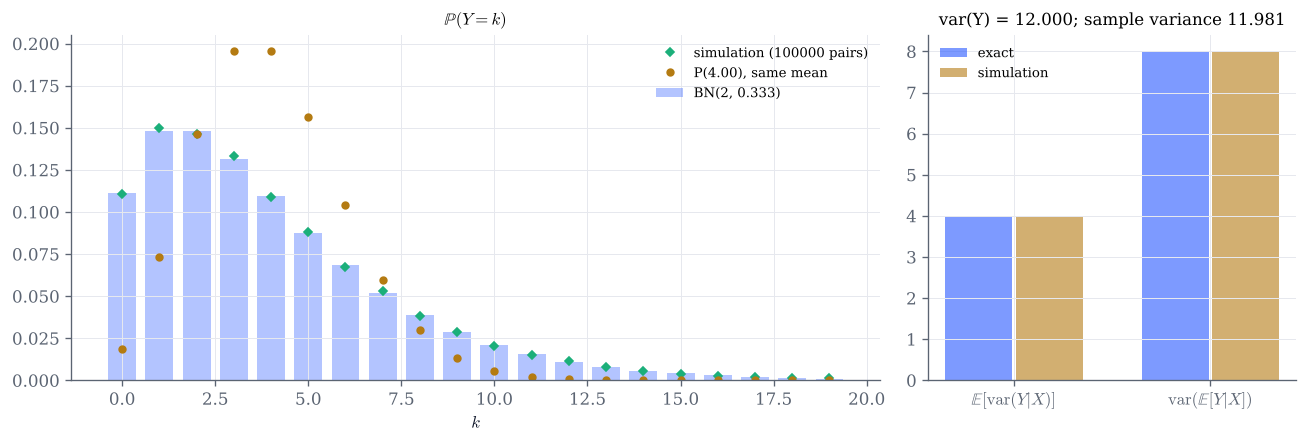

In [3]:
def mixture_demo(alpha=2.0, lam=0.5, log10_n=5.0, seed=2026):
    n = int(10 ** log10_n)
    x, y = sample_poisson_gamma(n, alpha, lam, seed=seed)
    kmax = int(np.quantile(y, 0.995)) + 2
    k = np.arange(kmax + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
    a1.bar(k, negbin_pmf(k, alpha, lam), color=COBALT, alpha=0.35, width=0.75,
           label=f"BN({alpha:g}, {lam / (lam + 1):.3f})")
    a1.plot(k, np.bincount(y, minlength=k.size)[: k.size] / n, "D", color=GREEN, ms=3.5, label=f"simulation ({n} pairs)")
    a1.plot(k, stats.poisson.pmf(k, alpha / lam), "o", color=GOLD, ms=4, label=f"P({alpha / lam:.2f}), same mean")
    a1.set(xlabel="$k$", title=r"$\mathbb{P}(Y=k)$")
    a1.legend(fontsize=8)
    exact = [alpha / lam, alpha / lam ** 2]
    est = [x.mean(), x.var()]
    pos = np.arange(2)
    a2.bar(pos - 0.18, exact, width=0.34, color=COBALT, alpha=0.6, label="exact")
    a2.bar(pos + 0.18, est, width=0.34, color=GOLD, alpha=0.6, label="simulation")
    a2.set_xticks(pos, [r"$\mathbb{E}[\mathrm{var}(Y|X)]$", r"$\mathrm{var}(\mathbb{E}[Y|X])$"])
    a2.set_title(f"var(Y) = {sum(exact):.3f}; sample variance {y.var():.3f}")
    a2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

mixture_demo()

In [4]:
# Explore: a small lambda spreads the proneness to failure, and the second term dominates.
interact(mixture_demo,
         alpha=FloatSlider(value=2.0, min=0.2, max=10.0, step=0.1, continuous_update=False, description="alpha"),
         lam=FloatSlider(value=0.5, min=0.1, max=5.0, step=0.05, continuous_update=False, description="lambda"),
         log10_n=FloatSlider(value=5.0, min=3.0, max=6.0, step=0.25, continuous_update=False, description="log10 n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 2. Estimating the proneness to failure from the number of maintenances

Knowing $Y=k$, the law of $X$ is $\Gamma(\alpha+k,\lambda+1)$, and the best estimate of $X$ in the sense of
Theorem 12.14 is $\mathbb E[X\mid Y=k]=\frac{\alpha+k}{\lambda+1}$. It lies between the prior mean $\frac\alpha\lambda$ and the
observation $k$: the data pull the estimate away from the prior, more strongly when the prior is spread out (small
$\lambda$). Left: the density of $X$, the conditional density given $Y=k$, and the histogram of the simulated $X$ among
the pairs with $Y=k$. Right: $h(k)=\mathbb E[X\mid Y=k]$, which is affine in $k$, against the simulated averages of $X$
given $Y=k$, with two standard errors.

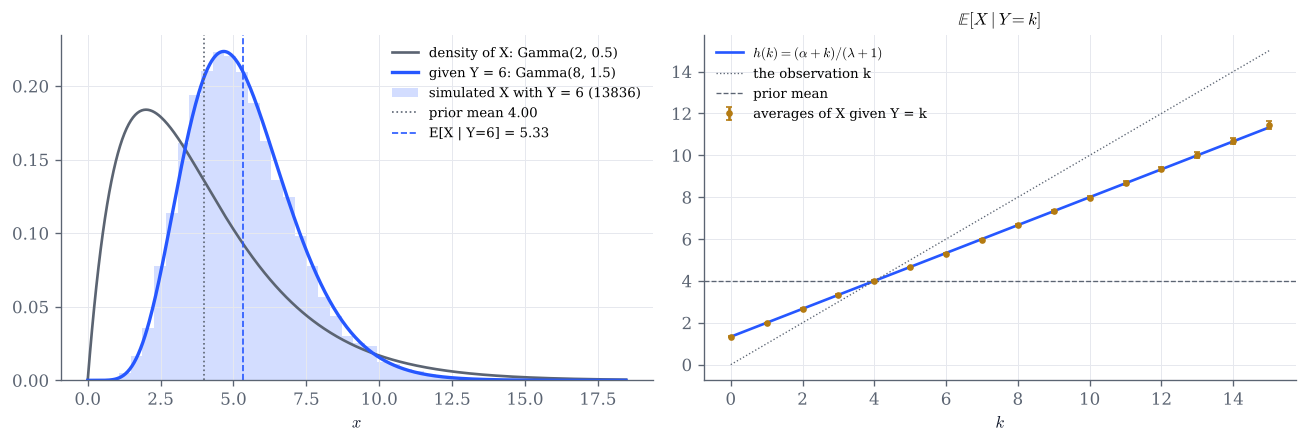

In [5]:
def posterior_demo(alpha=2.0, lam=0.5, k=6, seed=2026):
    n = 200_000
    x, y = sample_poisson_gamma(n, alpha, lam, seed=seed)
    shape, rate = gamma_posterior(k, alpha, lam)
    t = np.linspace(0, max(stats.gamma.ppf(0.999, alpha, scale=1 / lam), stats.gamma.ppf(0.999, shape, scale=1 / rate)), 500)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    a1.plot(t, stats.gamma.pdf(t, alpha, scale=1 / lam), color=GREY, label=f"density of X: Gamma({alpha:g}, {lam:g})")
    a1.plot(t, stats.gamma.pdf(t, shape, scale=1 / rate), color=COBALT, lw=2,
            label=f"given Y = {k}: Gamma({shape:g}, {rate:g})")
    sel = x[y == k]
    if sel.size > 1:
        a1.hist(sel, bins=40, density=True, color=COBALT, alpha=0.2, label=f"simulated X with Y = {k} ({sel.size})")
    a1.axvline(alpha / lam, color=GREY, ls=":", lw=1, label=f"prior mean {alpha / lam:.2f}")
    a1.axvline(shape / rate, color=COBALT, ls="--", lw=1, label=f"E[X | Y={k}] = {shape / rate:.2f}")
    a1.set(xlabel="$x$")
    a1.legend(fontsize=8)
    ks = np.arange(0, int(np.quantile(y, 0.99)) + 1)
    cnt = np.array([(y == j).sum() for j in ks])
    ok = cnt > 1
    means = np.array([x[y == j].mean() for j in ks[ok]])
    ses = np.array([x[y == j].std(ddof=1) / np.sqrt(c) for j, c in zip(ks[ok], cnt[ok])])
    a2.plot(ks, (alpha + ks) / (lam + 1), color=COBALT, label=r"$h(k)=(\alpha+k)/(\lambda+1)$")
    a2.errorbar(ks[ok], means, yerr=2 * ses, fmt="o", color=GOLD, ms=3, capsize=2, label="averages of X given Y = k")
    a2.plot(ks, ks, color=GREY, lw=0.8, ls=":", label="the observation k")
    a2.axhline(alpha / lam, color=GREY, lw=0.8, ls="--", label="prior mean")
    a2.set(xlabel="$k$", title=r"$\mathbb{E}[X\mid Y=k]$")
    a2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

posterior_demo()

In [6]:
# Explore: move k, and compare a spread-out prior (small lambda) with a concentrated one (large alpha and lambda).
interact(posterior_demo,
         alpha=FloatSlider(value=2.0, min=0.2, max=20.0, step=0.1, continuous_update=False, description="alpha"),
         lam=FloatSlider(value=0.5, min=0.1, max=5.0, step=0.05, continuous_update=False, description="lambda"),
         k=IntSlider(value=6, min=0, max=30, continuous_update=False, description="k"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 3. The best predictor in $L^2$ as a projection

A signal $X\sim\mathrm{Exp}(1)$ is received with Gaussian noise: $Y=X+W$, $W\sim\mathcal N(0,\sigma^2)$ (Example 12.15).
Among all functions $f(Y)$, the mean squared error $\mathbb E[(X-f(Y))^2]$ is smallest for $f=h$, $h(y)=\mathbb E[X\mid Y=y]$,
the orthogonal projection of $X$ onto $L^2(\Omega,\sigma(Y),\mathbb P)$ (Theorem 12.14, Remark 12.16); here $h$ is known in
closed form (Exercise 12.7). Projecting onto smaller subspaces gives larger errors: onto the span of $1$ and $Y$, the best
affine predictor; onto the span of the indicators of $K$ bins of $Y$, a regression whose coefficients are the averages of
$X$ over the bins. With finitely many samples the bin averages are noisy: too many bins and the error on new data grows
again. Left: samples, $h$, the affine predictor and the bin regression. Right: test errors of the bin regression against
$K$, for the chosen training size.

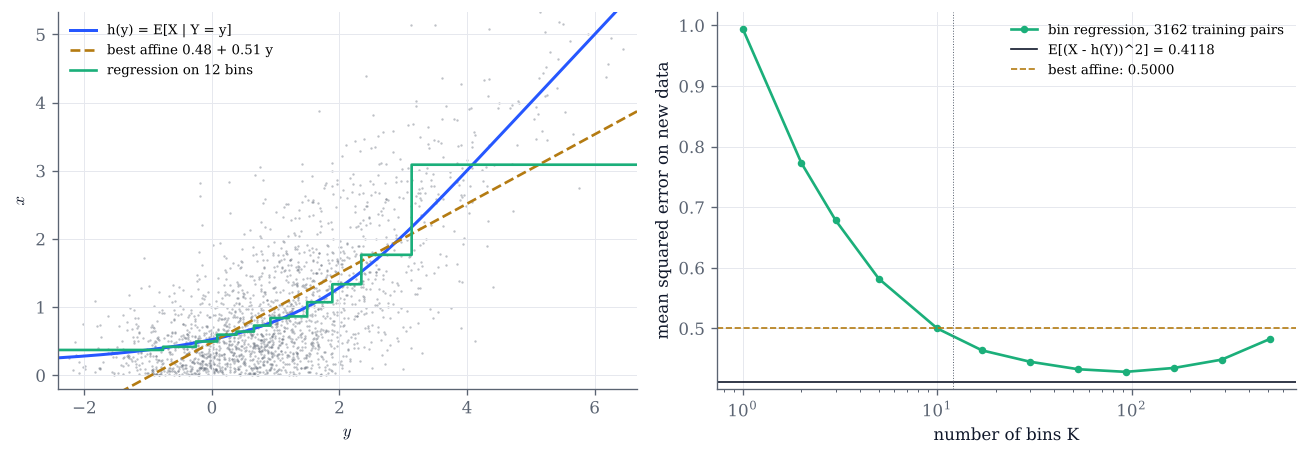

test errors: h 0.4113, affine 0.4980, 12 bins 0.4841


In [7]:
def quantile_edges(y, k):
    e = np.quantile(y, np.linspace(0, 1, k + 1))
    e[0], e[-1] = -np.inf, np.inf
    return e

def projection_demo(sigma=1.0, K=12, log10_nfit=3.5, seed=2026):
    nfit = int(10 ** log10_nfit)
    x, y = sample_signal(nfit, sigma, seed=seed)
    xt, yt = sample_signal(200_000, sigma, seed=seed + 1)
    a, b = affine_predictor(x, y)
    edges = quantile_edges(y, K)
    coef = bin_regression(x, y, edges)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9))
    m = min(nfit, 2000)
    a1.scatter(y[:m], x[:m], s=2, color=GREY, alpha=0.4, lw=0)
    lo, hi = np.quantile(yt, [0.002, 0.998])
    t = np.linspace(lo, hi, 600)
    a1.plot(t, signal_posterior_mean(t, sigma), color=COBALT, lw=1.8, label="h(y) = E[X | Y = y]")
    a1.plot(t, a + b * t, color=GOLD, ls="--", label=f"best affine {a:.2f} + {b:.2f} y")
    a1.plot(t, coef[bin_index(t, edges)], color=GREEN, drawstyle="steps-post", label=f"regression on {K} bins")
    a1.set(xlim=(lo, hi), ylim=(-0.2, np.quantile(x, 0.995)), xlabel="$y$", ylabel="$x$")
    a1.legend(fontsize=8, loc="upper left")
    ks = np.unique(np.round(np.geomspace(1, min(512, nfit // 2), 12)).astype(int))
    errs = [mse(xt, bin_regression(x, y, quantile_edges(y, k))[bin_index(yt, quantile_edges(y, k))]) for k in ks]
    e_h, e_aff = signal_mse(sigma), sigma ** 2 / (1 + sigma ** 2)
    a2.plot(ks, errs, "o-", color=GREEN, ms=3.5, label=f"bin regression, {nfit} training pairs")
    a2.axhline(e_h, color=INK, lw=1, label=f"E[(X - h(Y))^2] = {e_h:.4f}")
    a2.axhline(e_aff, color=GOLD, lw=1, ls="--", label=f"best affine: {e_aff:.4f}")
    a2.axvline(K, color=GREY, lw=0.6, ls=":")
    a2.set(xscale="log", xlabel="number of bins K", ylabel="mean squared error on new data")
    a2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    print(f"test errors: h {mse(xt, signal_posterior_mean(yt, sigma)):.4f}, affine {mse(xt, a + b * yt):.4f}, "
          f"{K} bins {mse(xt, coef[bin_index(yt, edges)]):.4f}")

projection_demo()

In [8]:
# Explore: with little noise h is almost the identity on y > 0; with much noise every predictor approaches E[X] = 1.
interact(projection_demo,
         sigma=FloatSlider(value=1.0, min=0.1, max=3.0, step=0.05, continuous_update=False, description="sigma"),
         K=IntSlider(value=12, min=1, max=200, continuous_update=False, description="bins K"),
         log10_nfit=FloatSlider(value=3.5, min=2.5, max=5.5, step=0.25, continuous_update=False, description="log10 n fit"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## Things to try

- In section 1, fix $\frac\alpha\lambda=4$ and increase both $\alpha$ and $\lambda$: the law of $Y$ approaches $\mathcal P(4)$. Which term of the law of total variance vanishes, and why?
- In section 1, with $\alpha=1$ the law of $X$ is exponential and $Y$ is geometric on $\mathbb N$: check it on the bars.
- In section 2, the estimate $\frac{\alpha+k}{\lambda+1}$ is a weighted average of the prior mean $\frac\alpha\lambda$ and of $k$. Find the weights, and check them by moving $\lambda$.
- In section 3, is $h$ ever below $0$ or above $y$? Explain both answers with the conditional law of $X$ given $Y=y$ (Exercise 12.7).
- In section 3, for $\sigma=1$ and $10^{3.5}$ training pairs, find the number of bins with the smallest test error. How does it move when the training set grows?